# 06 — Head Localization: Learned Sparse Mask

Learn a continuous mask over `(n_layers_tested, n_heads)` attention heads that selects the minimal set whose cross-language interchange (C++ source → Python destination) minimizes `KL(P_patched ∥ P_target)`.

**Objective:**
```
L = KL(P_patched ∥ P_target) + λ * Σ mask
```
- `P_patched`: next-token dist of dest prompt with mask-weighted head patch from source (C++)
- `P_target`: next-token dist of Python target prompt (same predicate as C++ source)
- Mask: `(n_layers_tested, n_heads)` values ∈ [0,1], initialized to 1, projected GD (no sigmoid)
- Selection: heads where mask > 0.5 after training

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-03-23 16:55:29 __main__ INFO     torch.__version__='2.6.0+cu124', torch.version.cuda='12.4'
2026-03-23 16:55:30 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=4, torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'
2026-03-23 16:55:30 __main__ INFO     transformers.__version__='5.3.0'


## Model init

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-03-23 16:55:34 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-23 16:55:34 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-03-23 16:55:34 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-03-23 16:55:34 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-23 16:55:34 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7ff175854b90>
2026-03-23 16:55:34 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fef129817f0> server_hostname='huggingface.co' timeout=10
2026-03-23 16:55:34 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-23 16:55:51 httpcore.connection DEBUG    close.started
2026-03-23 16:55:51 httpcore.connection DEBUG    close.complete
2026-03-23 16:55:51 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-23 16:55:51 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fef111a4b10>
2026-03-23 16:55:51 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fef129817f0> server_hostname='huggingface.co' timeout=10
2026-03-23 16:55:51 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fef1122c590>
2026-03-23 16:55:51 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-23 16:55:51 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-23 16:55:51 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load data

In [4]:
from src.goals.head_loc_data import HeadLocDataset

# Use "test" while mining is running; swap to mt.name.split("/")[-1] when done
# MODEL_NAME = "test"
MODEL_NAME = "Qwen2.5-Coder-32B-Instruct"

ds = HeadLocDataset.load(model_name=MODEL_NAME)
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]

pairs_with_pivots = [p for p in ds.pairs if p.pivot_instances]
print(f"Predicates : {len(ds.samples)}")
print(f"Pairs total: {len(ds.pairs)}")
print(f"Pairs w/ pivots: {len(pairs_with_pivots)}")
print(f"Pivot instances: {len(pivot_instances)}")

2026-03-23 16:55:55 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/Qwen2.5-Coder-32B-Instruct.json
Predicates : 21
Pairs total: 110
Pairs w/ pivots: 103
Pivot instances: 1480


In [5]:
from rich.console import Console
from rich.table import Table

console = Console(width=100, highlight=False)
table = Table(title=f"Pairs with pivot instances ({MODEL_NAME})", highlight=False)
table.add_column("Destination", style="cyan")
table.add_column("Source (C++)", style="magenta")
table.add_column("Type", style="yellow")
table.add_column("# Pivots", style="green", justify="right")

for p in ds.pairs:
    if p.pivot_instances:
        table.add_row(
            p.destination_predicate,
            p.source_predicate,
            p.variable_type,
            str(len(p.pivot_instances)),
        )

console.print(table)

       Pairs with pivot instances (Qwen2.5-Coder-32B-Instruct)       
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┓
┃ Destination            ┃ Source (C++)           ┃ Type ┃ # Pivots ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━┩
│ all_same               │ all_even               │ list │       23 │
│ all_even               │ all_same               │ list │       23 │
│ has_duplicates         │ all_even               │ list │       11 │
│ all_even               │ has_duplicates         │ list │        9 │
│ is_sorted              │ all_even               │ list │       22 │
│ all_even               │ is_sorted              │ list │       27 │
│ is_strictly_decreasing │ all_even               │ list │       29 │
│ all_even               │ is_strictly_decreasing │ list │       29 │
│ is_strictly_sorted     │ all_even               │ list │       25 │
│ all_even               │ is_strictly_sorted     │ list │       20 │
│ all_same               │ all_positive           │ list │       26 │
│ all_positive           │ all_same               │ list │       26 │
│ has_duplicates         │ all_positive           │ list │        9 │
│ all_positive           │ has_duplicates         │ list │        9 │
│ is_sorted              │ all_positive           │ list │       18 │
│ all_positive           │ is_sorted              │ list │       19 │
│ is_strictly_decreasing │ all_positive           │ list │       13 │
│ all_positive           │ is_strictly_decreasing │ list │       13 │
│ is_strictly_sorted     │ all_positive           │ list │       22 │
│ all_positive           │ is_strictly_sorted     │ list │       25 │
│ is_sorted              │ all_same               │ list │       26 │
│ all_same               │ is_sorted              │ list │       32 │
│ is_strictly_decreasing │ all_same               │ list │       26 │
│ all_same               │ is_strictly_decreasing │ list │       20 │
│ is_strictly_sorted     │ all_same               │ list │       23 │
│ all_same               │ is_strictly_sorted     │ list │       28 │
│ is_sorted              │ has_duplicates         │ list │       17 │
│ has_duplicates         │ is_sorted              │ list │        4 │
│ is_strictly_decreasing │ has_duplicates         │ list │       13 │
│ has_duplicates         │ is_strictly_decreasing │ list │       13 │
│ is_strictly_sorted     │ has_duplicates         │ list │       17 │
│ has_duplicates         │ is_strictly_sorted     │ list │        8 │
│ has_spaces             │ ends_with_vowel        │ str  │       17 │
│ ends_with_vowel        │ has_spaces             │ str  │       12 │
│ is_digit_string        │ ends_with_vowel        │ str  │        1 │
│ ends_with_vowel        │ is_digit_string        │ str  │        9 │
│ is_lower               │ ends_with_vowel        │ str  │        5 │
│ ends_with_vowel        │ is_lower               │ str  │       16 │
│ is_palindrome          │ ends_with_vowel        │ str  │       19 │
│ ends_with_vowel        │ is_palindrome          │ str  │       10 │
│ is_upper               │ ends_with_vowel        │ str  │        8 │
│ ends_with_vowel        │ is_upper               │ str  │        5 │
│ is_digit_string        │ has_spaces             │ str  │        2 │
│ has_spaces             │ is_digit_string        │ str  │        2 │
│ is_lower               │ has_spaces             │ str  │        2 │
│ has_spaces             │ is_lower               │ str  │        2 │
│ is_palindrome          │ has_spaces             │ str  │        4 │
│ has_spaces             │ is_palindrome          │ str  │        4 │
│ starts_with_vowel      │ has_spaces             │ str  │        7 │
│ has_spaces             │ starts_with_vowel      │ str  │       12 │
│ is_lower               │ is_digit_string        │ str  │       30 │
│ is_digit_string        │ is_lower               │ str  │       34 │
│ is_palindrome          │ is_digit_string        │ str  │       21 │
│ is_digit

In [6]:
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick the first pair that actually has pivot instances
pair, pi = next((p, pi) for p in ds.pairs for pi in p.pivot_instances)

print("PredicatePair:")
print(f"  destination_predicate : {pair.destination_predicate}  ← Python dest")
print(f"  source_predicate      : {pair.source_predicate}  ← C++ source / Python target")
print(f"  variable_type         : {pair.variable_type}")
print(f"  pivot count           : {len(pair.pivot_instances)}")

print("\nPivotInstance:")
print(f"  pivot_prefix     : {pi.pivot_prefix!r}")
print(f"  dest_top_token   : {pi.dest_top_token!r}")
print(f"  target_top_token : {pi.target_top_token!r}")
print(f"  tokens_diverge   : {pi.tokens_diverge}")

dest_sample = ds.get_sample(pair.destination_predicate)
targ_sample = ds.get_sample(pair.source_predicate)  # source_predicate = Python target

src_prompt  = build_cpp_prompt(mt, ds.get_sample(pair.source_predicate), include_docstring=True)
dest_prompt = build_python_prompt(mt, dest_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True)
targ_prompt = build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True)

print("\n--- C++ source prompt ---")
rich_print(src_prompt)
print("\n--- Python dest prompt ---")
rich_print(dest_prompt)
print("\n--- Python target prompt  ---")
rich_print(targ_prompt)

PredicatePair:
  destination_predicate : all_same  ← Python dest
  source_predicate      : all_even  ← C++ source / Python target
  variable_type         : list[int]
  pivot count           : 23

PivotInstance:
  pivot_prefix     : 'all(x'
  dest_top_token   : ' =='
  target_top_token : ' %'
  tokens_diverge   : True

--- C++ source prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if every element in lst is even.
bool allEven(vector<int> lst) { return


--- Python dest prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_same(lst: list) -> bool:
    """Return True if all elements in lst are equal."""
    return all(x


--- Python target prompt  ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_even(lst: list) -> bool:
    """Return True if every element in lst is even."""
    return all(x

In [7]:
selected_pivot_instances = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_pivot_instances)

10

## Cache pivot data (one-time, ~2 forward passes per instance)

In [8]:
from src.goals.head_loc_attn import cache_pivot_data

# LAYERS = list(range(0, mt.n_layer))
LAYERS = list(range(6, 40))

pivot_caches = cache_pivot_data(mt, selected_pivot_instances, ds, layers=LAYERS)

print(f"Cached {len(pivot_caches)} instances")
c = pivot_caches[0]
print(f"per_head_deltas shape: {c.per_head_deltas.shape}")  # (n_layers, n_heads, n_embd)
print(f"log_p_target shape:    {c.log_p_target.shape}")
print(f"src_sample predicate:  {c.src_sample.predicate_name}")
print(f"dest_sample predicate: {c.dest_sample.predicate_name}")


2026-03-20 16:53:04 src.goals.head_loc_attn INFO     cache_pivot_data: 10 instances | precompute_deltas=True | cache_batch_size=64


2026-03-20 16:53:05 src.goals.head_loc_attn DEBUG      targ probs: 10/10
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      deltas: 10/10
2026-03-20 16:53:08 src.goals.head_loc_attn INFO     cache_pivot_data: deltas precomputed and cached
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 1/10: is_lower ← is_palindrome prefix='s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 2/10: is_lower ← is_palindrome prefix='bool(s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 3/10: is_lower ← is_palindrome prefix='not not s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 4/10: is_lower ← is_palindrome prefix='True and s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 5/10: is_lower ← is_palindrome prefix='False or s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 6/10: is_upper ← is_palindrome prefix='s == s'
2026-03-20 16:53:08 src.

---
## Augmented training

`augment_pivot_caches` applies **one random augmentation per instance** (1× expansion) and returns a fresh set of lazy `PivotCache` objects (no precomputed deltas).

Augmentation type is sampled with weights:

| Type | Weight | What changes |
|------|--------|--------------|
| `source_lang` | 55% | `src_prompt` swapped to Java / Rust / Haskell / Prolog; `log_p_target` reused |
| `variable_rename` | 35% | variable renamed via `_VAR_VOCAB`; `src_prompt`, `dest_prompt`, `pivot_prefix`, `log_p_target` updated; falls back to `source_lang` if var not in vocab |
| `toggle_type_hints` | 10% | Python type annotations stripped from `def` line; `src_prompt`, `dest_prompt`, `log_p_target` updated |

**Requirements:** `pivot_caches` must have `per_head_deltas=None` (i.e., `cache_pivot_data` called with `precompute_deltas=False`).  
When used in training (`--augment`), `augment_pivot_caches` is called at the start of every epoch, so the model sees a different surface form each time.

In [8]:
selected_instances_tmp = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_upper"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_instances_tmp)

5

In [11]:
from src.goals.head_loc_attn import cache_pivot_data

LAYERS = list(range(mt.n_layer))
pivot_caches_tmp = cache_pivot_data(
    mt, selected_instances_tmp, ds, layers=LAYERS,
    precompute_deltas=False, cache_batch_size=8,
)


2026-03-23 16:56:45 src.goals.head_loc_attn INFO     cache_pivot_data: 5 instances | precompute_deltas=False | cache_batch_size=8


2026-03-23 16:56:48 src.goals.head_loc_attn DEBUG      targ probs: 5/5
2026-03-23 16:56:48 src.goals.head_loc_attn DEBUG      Building cache 1/5: is_palindrome ← is_upper prefix='s == s'
2026-03-23 16:56:48 src.goals.head_loc_attn DEBUG      Building cache 2/5: is_palindrome ← is_upper prefix='bool(s == s'
2026-03-23 16:56:48 src.goals.head_loc_attn DEBUG      Building cache 3/5: is_palindrome ← is_upper prefix='not not s == s'
2026-03-23 16:56:48 src.goals.head_loc_attn DEBUG      Building cache 4/5: is_palindrome ← is_upper prefix='True and s == s'
2026-03-23 16:56:48 src.goals.head_loc_attn DEBUG      Building cache 5/5: is_palindrome ← is_upper prefix='False or s == s'
2026-03-23 16:56:48 src.goals.head_loc_attn INFO     cache_pivot_data: cached 5 pivot instances


In [17]:
from src.goals.head_loc_attn import augment_pivot_caches

# Requires pivot_caches with lazy deltas (precompute_deltas=False).
# If not already computed:
#   pivot_caches = cache_pivot_data(mt, selected_pivot_instances, ds, layers=LAYERS, precompute_deltas=False)

AUG_INSTANCES = 10  # test on a small slice

aug_caches = augment_pivot_caches(
    mt,
    pivot_caches=pivot_caches_tmp[:AUG_INSTANCES],
    cache_batch_size=8,
)

print(f"Input caches    : {min(AUG_INSTANCES, len(pivot_caches_tmp))}")
print(f"Augmented caches: {len(aug_caches)}  (should equal {len(pivot_caches_tmp[:AUG_INSTANCES])} — 1x expansion)")
print(f"All lazy        : {all(c.per_head_deltas is None for c in aug_caches)}")


2026-03-23 17:04:10 src.goals.head_loc_attn DEBUG    augment_pivot_caches: recomputing log_p_target for 3/5 instances


2026-03-23 17:04:10 src.goals.head_loc_attn INFO     augment_pivot_caches: 5 caches augmented (3 log_p recomputed, 2 reused)
Input caches    : 5
Augmented caches: 5  (should equal 5 — 1x expansion)
All lazy        : True


In [18]:
# Inspect augmented prompts side-by-side with originals
# orig.src_prompt is None when pivot_caches were built with precompute_deltas=True —
# now we can use pivot_caches_tmp[i].src_sample to rebuild it directly.
from rich import box
from rich.console import Console
from rich.table import Table
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

_console = Console(width=160, highlight=False)

SHOW = 10

for i in range(min(SHOW, len(aug_caches))):
    aug = aug_caches[i]

    orig_cache = pivot_caches_tmp[i]
    orig_src_prompt = orig_cache.src_prompt
    if orig_src_prompt is None:
        # precompute_deltas=True path: rebuild from stored src_sample
        orig_src_prompt = build_cpp_prompt(mt, orig_cache.src_sample)

    orig_dest_prompt = orig_cache.dest_prompt
    # Target prompt = Python prompt for the source predicate (targ_sample == src_sample)
    targ_prompt = build_python_prompt(
        mt, aug.src_sample, aug.pivot_instance.pivot_prefix
    )

    table = Table(highlight=False, show_header=True, pad_edge=False, box=box.HORIZONTALS)
    table.add_column("variant", style="cyan", width=12, no_wrap=True)
    table.add_column("src prompt (last 300 chars)", style="magenta", width=65)
    table.add_column("dest prompt (last 300 chars)", style="green", width=65)
    table.add_column("target prompt (last 300 chars)", style="yellow", width=65)
    table.add_row("original",  orig_src_prompt[-300:],    orig_dest_prompt[-300:], "")
    table.add_section()
    table.add_row("augmented", aug.src_prompt[-300:],     aug.dest_prompt[-300:],  targ_prompt[-300:])

    _console.print(f"[bold]Cache {i}[/bold]  pair: {orig_cache.src_sample.predicate_name} -> {orig_cache.dest_sample.predicate_name}")
    _console.print(table)


Cache 0  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        t in programming. When completing code, ensure                                                          
   completing code, ensure proper syntax and logical    proper syntax and logical correctness. Make sure                                                        
   correctness. Make sure to have all codes inside      to have all codes inside the <code> </code>                                                             
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return s == s                                                                                       
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   stant proficient in programming. When completing     ompleting code, ensure proper syntax and logical     hen completing code, ensure proper syntax and      
   code, ensure proper syntax and logical               correctness. Make sure to have all codes inside      logical correctness. Make sure to have all codes   
   correctness. Make sure to have all codes inside      the <code> </code> tags.<|im_end|>                   inside the <code> </code> tags.<|im_end|>          
   the <code> </code> tags.<|im_end|>                   <|im_start|>user                                     <|im_start|>user                                   
   <|im_start|>user                                     Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   Complete the C++ function below.<|im_end|>           <|im_start|>assistant                                <|im_start|>assistant                              
   <|im_start|>assistant                                <code>                                               <code>                                             
   <code>                                               def is_palindrome(input_str: str) -> bool:           def is_upper(input_str: str) -> bool:              
   bool isUpper(string input_str) { return                  return input_str == input_str                        return input_str == input_str                  
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 1  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        programming. When completing code, ensure proper                                                        
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return bool(s == s                                                                                  
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        t in programming. When completing code, ensure       icient in programming. When completing code,       
   completing code, ensure proper syntax and logical    proper syntax and logical correctness. Make sure     ensure proper syntax and logical correctness. Make 
   correctness. Make sure to have all codes inside      to have all codes inside the <code> </code>          sure to have all codes inside the <code> </code>   
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   bool isUpper(string s) { return                      def is_palindrome(s) -> bool:                        def is_upper(s) -> bool:                           
                                                            return bool(s == s                                   return bool(s == s                             
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 2  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        gramming. When completing code, ensure proper                                                           
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return not not s == s                                                                               
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        n programming. When completing code, ensure proper   ent in programming. When completing code, ensure   
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have    proper syntax and logical correctness. Make sure   
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                  to have all codes inside the <code> </code>        
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   bool isUpper(string s) { return                      def is_palindrome(s) -> bool:                        def is_upper(s) -> bool:                           
                                                            return not not s == s                                return not not s == s                          
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 3  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        ramming. When completing code, ensure proper                                                            
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return True and s == s                                                                              
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ant proficient in programming. When completing       ramming. When completing code, ensure proper          programming. When completing code, ensure proper  
   code, ensure proper syntax and logical               syntax and logical correctness. Make sure to have    syntax and logical correctness. Make sure to have  
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                  all codes inside the <code> </code>                
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the Haskell function below.<|im_end|>       Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   isUpper :: String -> Bool                            def is_palindrome(s: str) -> bool:                   def is_upper(s: str) -> bool:                      
   isUpper s =                                              return True and s == s                               return True and s == s                         
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Cache 4  pair: is_upper -> is_palindrome

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   src prompt (last 300 chars)                          dest prompt (last 300 chars)                         target prompt (last 300 chars)                     
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ful assistant proficient in programming. When        ramming. When completing code, ensure proper                                                            
   completing code, ensure proper syntax and logical    syntax and logical correctness. Make sure to have                                                       
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                                                                     
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                                                                         
   <|im_start|>user                                     <|im_start|>user                                                                                        
   Complete the C++ function below.<|im_end|>           Complete the Python function below.<|im_end|>                                                           
   <|im_start|>assistant                                <|im_start|>assistant                                                                                   
   <code>                                               <code>                                                                                                  
   bool isUpper(string s) { return                      def is_palindrome(s: str) -> bool:                                                                      
                                                            return False or s == s                                                                              
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
   ant proficient in programming. When completing       ramming. When completing code, ensure proper          programming. When completing code, ensure proper  
   code, ensure proper syntax and logical               syntax and logical correctness. Make sure to have    syntax and logical correctness. Make sure to have  
   correctness. Make sure to have all codes inside      all codes inside the <code> </code>                  all codes inside the <code> </code>                
   the <code> </code> tags.<|im_end|>                   tags.<|im_end|>                                      tags.<|im_end|>                                    
   <|im_start|>user                                     <|im_start|>user                                     <|im_start|>user                                   
   Complete the Haskell function below.<|im_end|>       Complete the Python function below.<|im_end|>        Complete the Python function below.<|im_end|>      
   <|im_start|>assistant                                <|im_start|>assistant                                <|im_start|>assistant                              
   <code>                                               <code>                                               <code>                                             
   isUpper :: String -> Bool                            def is_palindrome(s: str) -> bool:                   def is_upper(s: str) -> bool:                      
   isUpper s =                                              return False or s == s                               return False or s == s                         
 ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

## Train the head mask

In [ ]:
from src.goals.head_loc_attn import train_head_mask

mask, history = train_head_mask(
    mt,
    pivot_caches,
    layers=LAYERS,
    n_epochs=100,
    lr=1e-2,
    lambda_sparse=20,
    batch_size=16,
)

n_heads = mt.model.config.num_attention_heads
print(f"\nFinal active heads: {mask.n_active()} / {len(LAYERS) * n_heads}")
print("Selected:", mask.selected_heads(LAYERS))

2026-03-18 23:06:58 src.goals.head_loc_attn INFO     train_head_mask: 64L × 40H = 2560 mask params | 43 instances | batch_size=16 (3 batches/epoch) | 100 epochs | lr=0.01 λ=20 | lazy_deltas=False
2026-03-18 23:07:08 src.goals.head_loc_attn INFO       Epoch   1/100: KL=19.8051  sparse=19.8116  total=39.6167  n_active=2560
2026-03-18 23:07:45 src.goals.head_loc_attn INFO       Epoch   5/100: KL=19.4278  sparse=17.6367  total=37.0645  n_active=2560
2026-03-18 23:08:33 src.goals.head_loc_attn INFO       Epoch  10/100: KL=18.7463  sparse=15.0035  total=33.7499  n_active=2560
2026-03-18 23:09:21 src.goals.head_loc_attn INFO       Epoch  15/100: KL=18.1104  sparse=12.4230  total=30.5334  n_active=2559
2026-03-18 23:10:08 src.goals.head_loc_attn INFO       Epoch  20/100: KL=17.5894  sparse=9.9215  total=27.5108  n_active=615
2026-03-18 23:10:55 src.goals.head_loc_attn INFO       Epoch  25/100: KL=17.1240  sparse=7.5761  total=24.7001  n_active=423
2026-03-18 23:11:42 src.goals.head_loc_attn IN

## Training curves

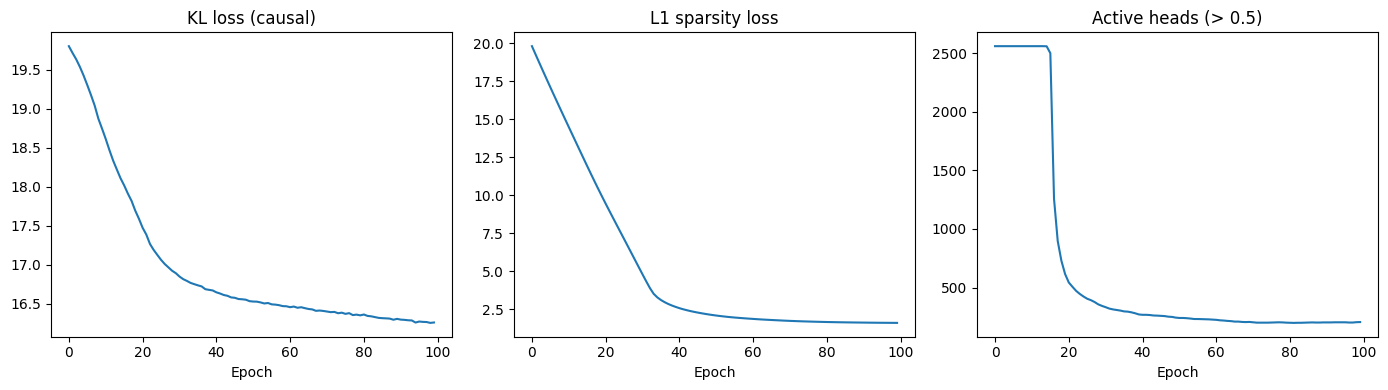

In [ ]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history.loss_causal)
axes[0].set_title("KL loss (causal)")
axes[0].set_xlabel("Epoch")

axes[1].plot(history.loss_sparse)
axes[1].set_title("L1 sparsity loss")
axes[1].set_xlabel("Epoch")

axes[2].plot(history.n_active)
axes[2].set_title("Active heads (> 0.5)")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## Mask heatmap

2026-03-18 23:22:59 matplotlib.colorbar DEBUG    locator: <matplotlib.ticker.AutoLocator object at 0x7faed036ce90>


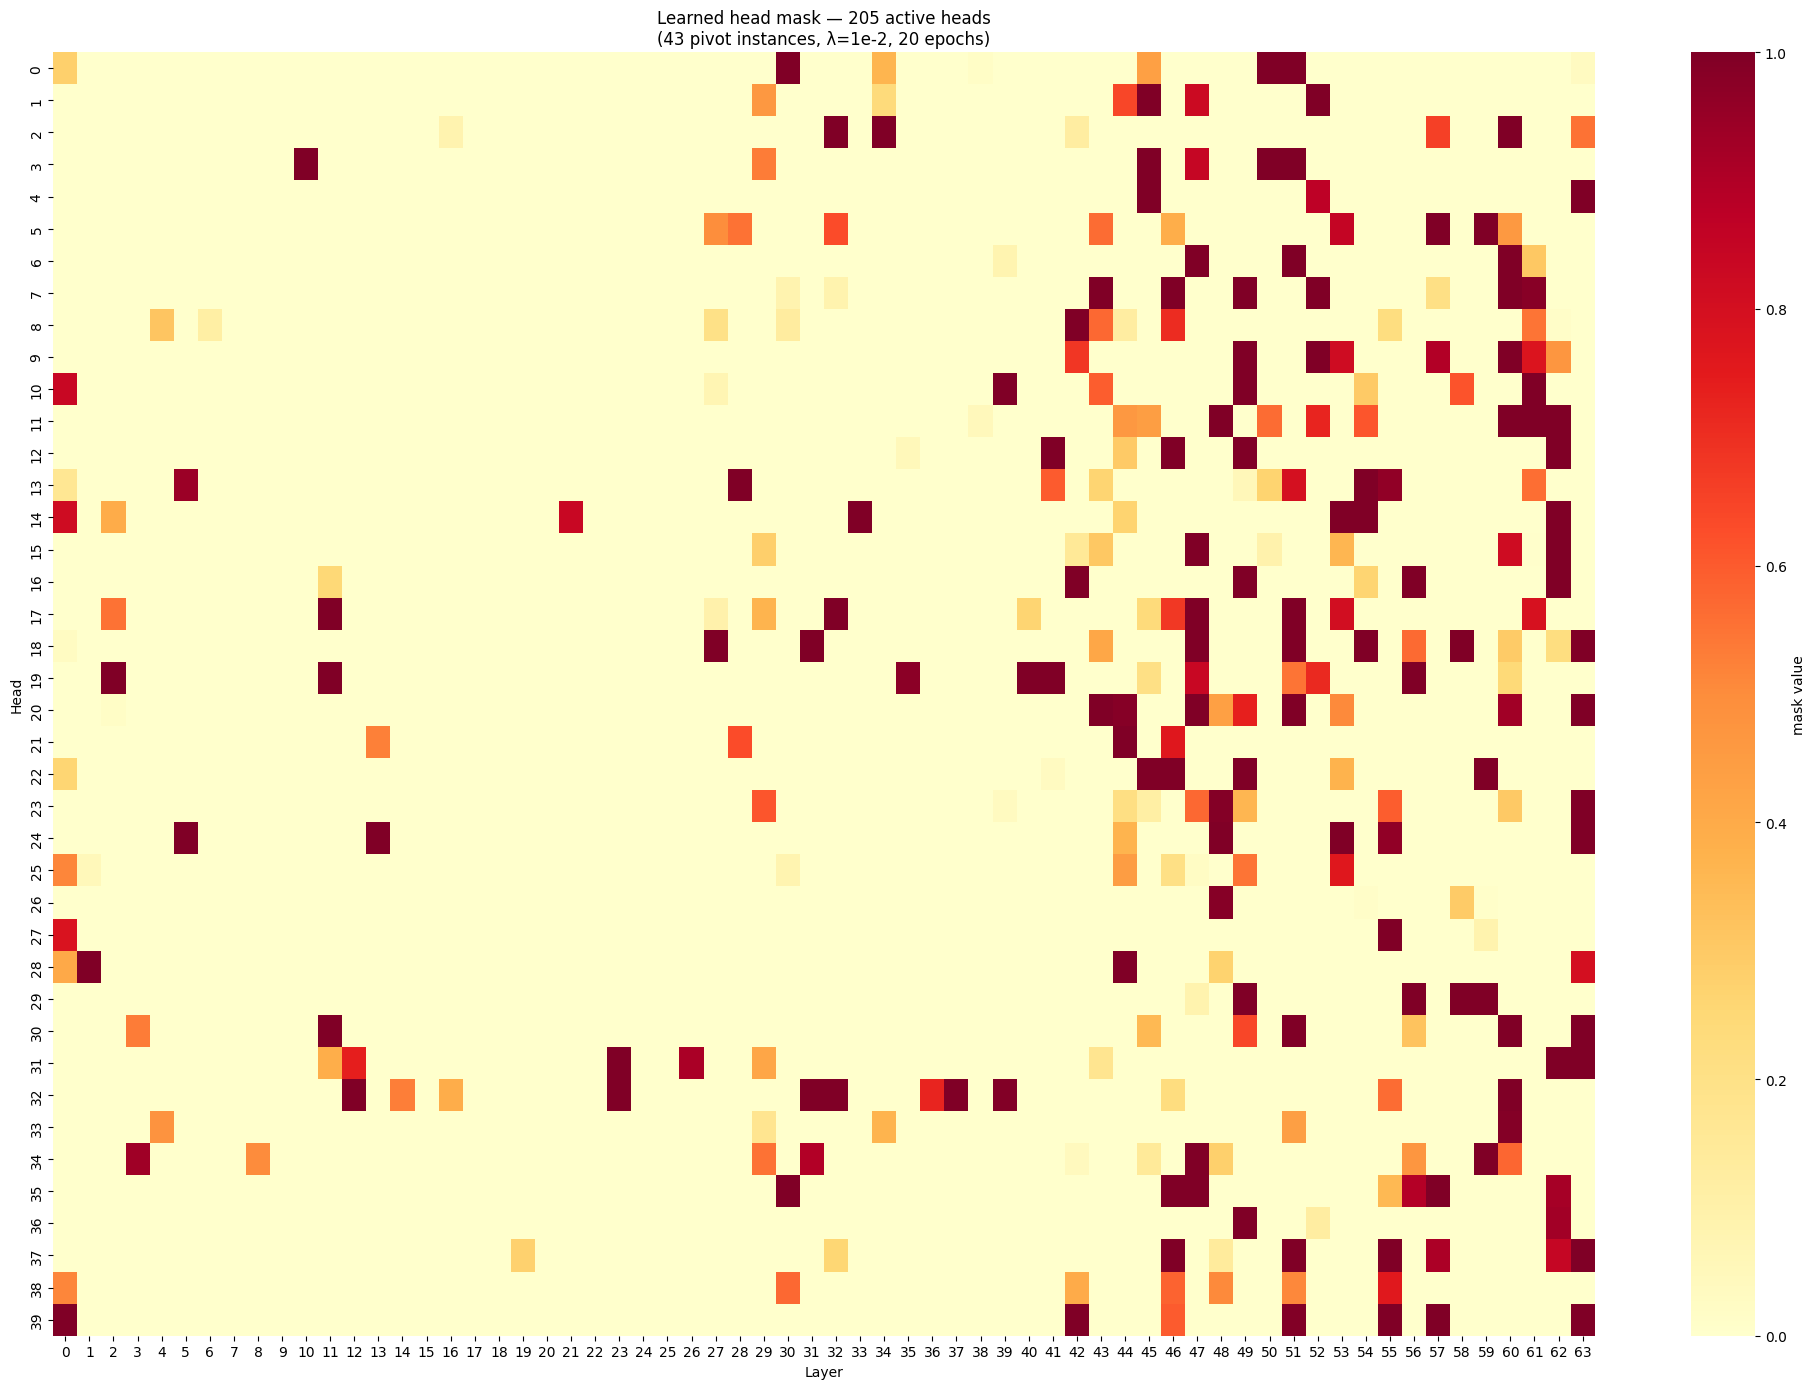


Top 10 heads by mask value:
  layer=59 head=22: 1.0000
  layer=1 head=28: 1.0000
  layer=49 head=10: 1.0000
  layer=45 head=22: 1.0000
  layer=48 head=24: 1.0000
  layer=30 head=0: 1.0000
  layer=54 head=14: 1.0000
  layer=31 head=32: 1.0000
  layer=54 head=13: 1.0000
  layer=59 head=5: 1.0000


In [ ]:
mask_vals = mask.values.detach().cpu().numpy()  # (n_layers_tested, n_heads)
import numpy as np

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    mask_vals.T, ax=ax, cmap="YlOrRd", vmin=0, vmax=1,
    xticklabels=[str(l) for l in LAYERS],
    yticklabels=range(n_heads),
    cbar_kws={"label": "mask value"},
)
ax.set_title(
    f"Learned head mask — {mask.n_active()} active heads\n"
    f"({len(pivot_instances)} pivot instances, λ=1e-2, 20 epochs)"
)
ax.set_xlabel("Layer")
ax.set_ylabel("Head")
plt.tight_layout()
plt.show()

print("\nTop 10 heads by mask value:")
flat = mask_vals.flatten()
for idx in np.argsort(flat)[::-1][:10]:
    li, h = divmod(int(idx), n_heads)
    print(f"  layer={LAYERS[li]} head={h}: {mask_vals[li, h]:.4f}")

## Sparsity sweep: λ vs. n_active vs. KL (Pareto frontier)

17:14:02 INFO src.goals.head_loc_attn — train_head_mask: 40L × 40H = 1600 mask params | 10 instances | 20 epochs | lr=0.01 λ=0.001
17:14:04 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.6388  sparse=1.5710  total=5.2098  n_active=1600
17:14:14 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1130  sparse=1.4074  total=3.5204  n_active=1574
17:14:27 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7670  sparse=1.2269  total=2.9938  n_active=1357
17:14:39 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5683  sparse=1.0787  total=2.6470  n_active=1185
17:14:51 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4358  sparse=0.9634  total=2.3993  n_active=1037
17:14:51 INFO src.goals.head_loc_attn — train_head_mask done: 1037 active heads → [(20, 3), (20, 4), (20, 5), (20, 11), (20, 15), (20, 18), (20, 25), (20, 27), (20, 28), (20, 33), (20, 34), (20, 39), (21, 1), (21, 4), (21, 6), (21, 8), (21, 9), (21, 11), (21, 13), (21, 15), (21, 18), (21, 26), (21, 27), (21, 31), (21,

  λ=1e-03: n_active=1037  KL=1.4358


17:14:53 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5949  sparse=7.7937  total=11.3886  n_active=1600
17:15:03 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0779  sparse=6.3495  total=8.4274  n_active=1507
17:15:14 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7208  sparse=4.5194  total=6.2402  n_active=933
17:15:26 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5331  sparse=3.2795  total=4.8126  n_active=665
17:15:38 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4172  sparse=2.5283  total=3.9455  n_active=506
17:15:38 INFO src.goals.head_loc_attn — train_head_mask done: 506 active heads → [(21, 32), (22, 29), (23, 6), (23, 23), (23, 26), (23, 31), (23, 35), (25, 38), (26, 9), (26, 27), (26, 31), (27, 8), (27, 10), (27, 17), (27, 18), (27, 19), (27, 21), (27, 23), (28, 4), (28, 5), (28, 12), (28, 13), (28, 17), (28, 21), (28, 23), (28, 24), (28, 25), (29, 1), (29, 2), (29, 4), (29, 17), (29, 18), (29, 19), (29, 22), (29, 23), (29, 31), (29, 39), (30, 0),

  λ=5e-03: n_active= 506  KL=1.4172


17:15:40 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5640  sparse=15.5110  total=19.0750  n_active=1600
17:15:49 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0515  sparse=11.7952  total=13.8468  n_active=1445
17:16:01 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7356  sparse=7.0230  total=8.7586  n_active=647
17:16:13 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5843  sparse=4.2879  total=5.8722  n_active=388
17:16:24 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4716  sparse=2.9599  total=4.4315  n_active=265
17:16:24 INFO src.goals.head_loc_attn — train_head_mask done: 265 active heads → [(23, 6), (27, 10), (27, 17), (27, 18), (28, 5), (28, 13), (29, 1), (29, 18), (29, 19), (29, 23), (30, 0), (30, 8), (30, 23), (30, 25), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 31), (31, 32), (31, 34), (32, 1), (32, 3), (32, 8), (32, 13), (32, 25), (32, 26), (32, 32), (32, 33), (33, 26), (33, 30), (33, 34), (34, 3), (34, 4), (34, 22), (34, 25

  λ=1e-02: n_active= 265  KL=1.4716


17:16:27 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5192  sparse=30.8728  total=34.3920  n_active=1600
17:16:36 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1125  sparse=21.8097  total=23.9222  n_active=1349
17:16:48 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.8070  sparse=10.2562  total=12.0632  n_active=381
17:17:00 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.6782  sparse=4.9416  total=6.6198  n_active=202
17:17:13 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.6196  sparse=3.2284  total=4.8480  n_active=134
17:17:13 INFO src.goals.head_loc_attn — train_head_mask done: 134 active heads → [(27, 10), (29, 1), (29, 18), (30, 8), (30, 23), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 32), (31, 34), (32, 3), (33, 34), (34, 22), (34, 25), (35, 13), (35, 39), (38, 0), (38, 7), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (39, 34), (40, 3), (40, 8), (40, 11), (40, 13), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (42, 11), (43, 5)

  λ=2e-02: n_active= 134  KL=1.6196


17:17:15 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5004  sparse=76.7545  total=80.2549  n_active=1600
17:17:25 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.3505  sparse=49.4677  total=51.8182  n_active=1125
17:17:37 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=2.0425  sparse=15.5258  total=17.5683  n_active=139
17:17:52 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=2.0015  sparse=5.2949  total=7.2964  n_active=79
17:18:04 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.9817  sparse=3.4552  total=5.4369  n_active=64
17:18:04 INFO src.goals.head_loc_attn — train_head_mask done: 64 active heads → [(30, 8), (30, 35), (31, 18), (31, 32), (38, 0), (39, 8), (39, 9), (39, 31), (39, 32), (43, 15), (44, 21), (45, 1), (45, 3), (45, 17), (45, 18), (45, 31), (46, 7), (46, 8), (46, 12), (46, 19), (46, 20), (46, 25), (46, 35), (46, 39), (47, 8), (47, 32), (47, 33), (47, 34), (48, 24), (48, 25), (48, 26), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 15), (49, 16),

  λ=5e-02: n_active=  64  KL=1.9817


17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSansMandaic-Regular.ttf', name='Noto Sans Mandaic', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/freefont/FreeMonoBoldOblique.ttf', name='FreeMono', style='oblique', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/tlwg/TlwgTypewriter-Oblique.otf', name='Tlwg Typewriter', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/ipafont-mincho/ipamp.ttf', name='IPAPMincho', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matpl

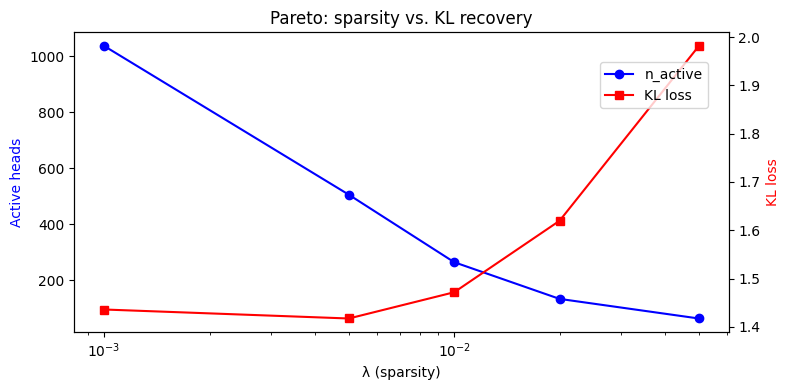

In [ ]:
# lambdas = [1e-3, 5e-3, 1e-2, 2e-2, 5e-2]
lambdas = [1, 5, 10, 20, 50, 75, 100]
pareto = []

for lam in lambdas:
    m, h = train_head_mask(mt, pivot_caches, layers=LAYERS, n_epochs=20, lr=1e-2, lambda_sparse=lam)
    pareto.append((lam, m.n_active(), h.loss_causal[-1]))
    print(f"  λ={lam:.0e}: n_active={m.n_active():4d}  KL={h.loss_causal[-1]:.4f}")

lams, n_acts, kls = zip(*pareto)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.semilogx(lams, n_acts, "b-o", label="n_active")
ax2.semilogx(lams, kls, "r-s", label="KL loss")
ax1.set_xlabel("λ (sparsity)")
ax1.set_ylabel("Active heads", color="b")
ax2.set_ylabel("KL loss", color="r")
ax1.set_title("Pareto: sparsity vs. KL recovery")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.85))
plt.tight_layout()
plt.show()

---
## Load saved mask (from `train_head_mask.py`)

Use this section when loading a mask trained by the script rather than training inline above.

In [19]:
import os
import torch
from src.goals.head_loc_attn import HeadMask

MASK_PATH = "../results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt"

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    mask.values[0 : 25] = 0  # zero out early layers
    mask.values[56 : ] = 0  # zero out late layers

selected_heads = mask.selected_heads(LAYERS)
print(f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)")
print(f"  Active heads (mask > 0.5): {len(selected_heads)}")
print(f"  Selected heads: {selected_heads}")

Loaded checkpoint from ../results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.5): 141
  Selected heads: [(28, 13), (29, 1), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (30, 38), (31, 18), (31, 19), (31, 32), (32, 3), (32, 13), (33, 34), (34, 30), (34, 33), (35, 13), (35, 36), (35, 39), (37, 11), (37, 15), (38, 0), (38, 2), (38, 26), (39, 2), (39, 4), (39, 6), (39, 9), (39, 14), (39, 31), (39, 32), (39, 33), (39, 34), (40, 2), (40, 3), (40, 8), (40, 9), (40, 11), (40, 19), (40, 30), (40, 32), (40, 34), (40, 39), (41, 6), (41, 9), (41, 12), (41, 13), (41, 21), (41, 32), (42, 5), (42, 14), (42, 39), (43, 5), (43, 8), (43, 11), (43, 12), (43, 13), (43, 15), (43, 24), (43, 30), (43, 32), (44, 7), (44, 12), (44, 13), (44, 14), (44, 18), (44, 22), (44, 38), (45, 1), (45, 15), (45, 17), (45, 18), (45, 20), (45, 21), (45, 22), (45, 23), (45, 31), (45, 32), (45, 33), (45, 34), (46, 0), (46, 1), (46, 7), (46, 8), (

In [20]:
mask.values.shape

torch.Size([64, 40])

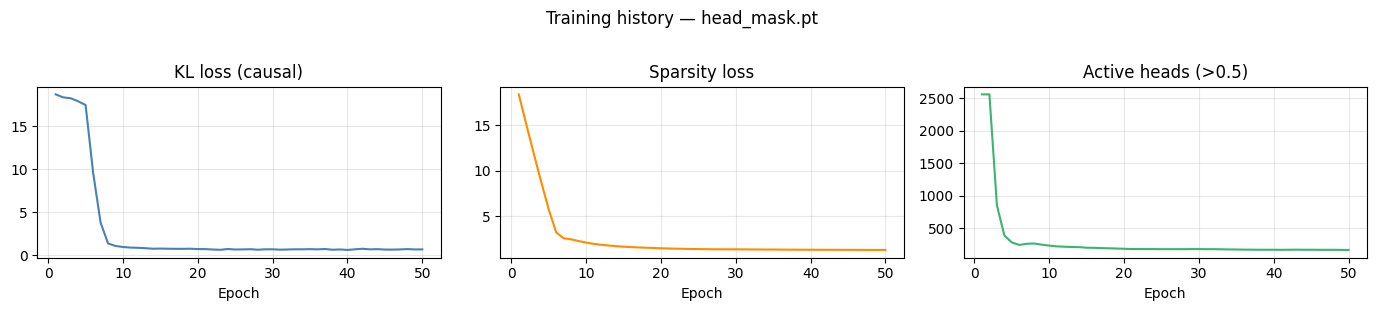

In [22]:
# Training curves from the checkpoint
from matplotlib import pyplot as plt
import numpy as np

plt.rcdefaults()

h = ckpt["history"]
xs = np.arange(1, len(h["loss_total"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(xs, h["loss_causal"],  color="steelblue");  axes[0].set_title("KL loss (causal)")
axes[1].plot(xs, h["loss_sparse"],  color="darkorange"); axes[1].set_title("Sparsity loss")
axes[2].plot(xs, h["n_active"],     color="mediumseagreen"); axes[2].set_title("Active heads (>0.5)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.suptitle(f"Training history — {os.path.basename(MASK_PATH)}", y=1.02)
plt.tight_layout()
plt.show()

In [23]:
len(selected_heads)

141

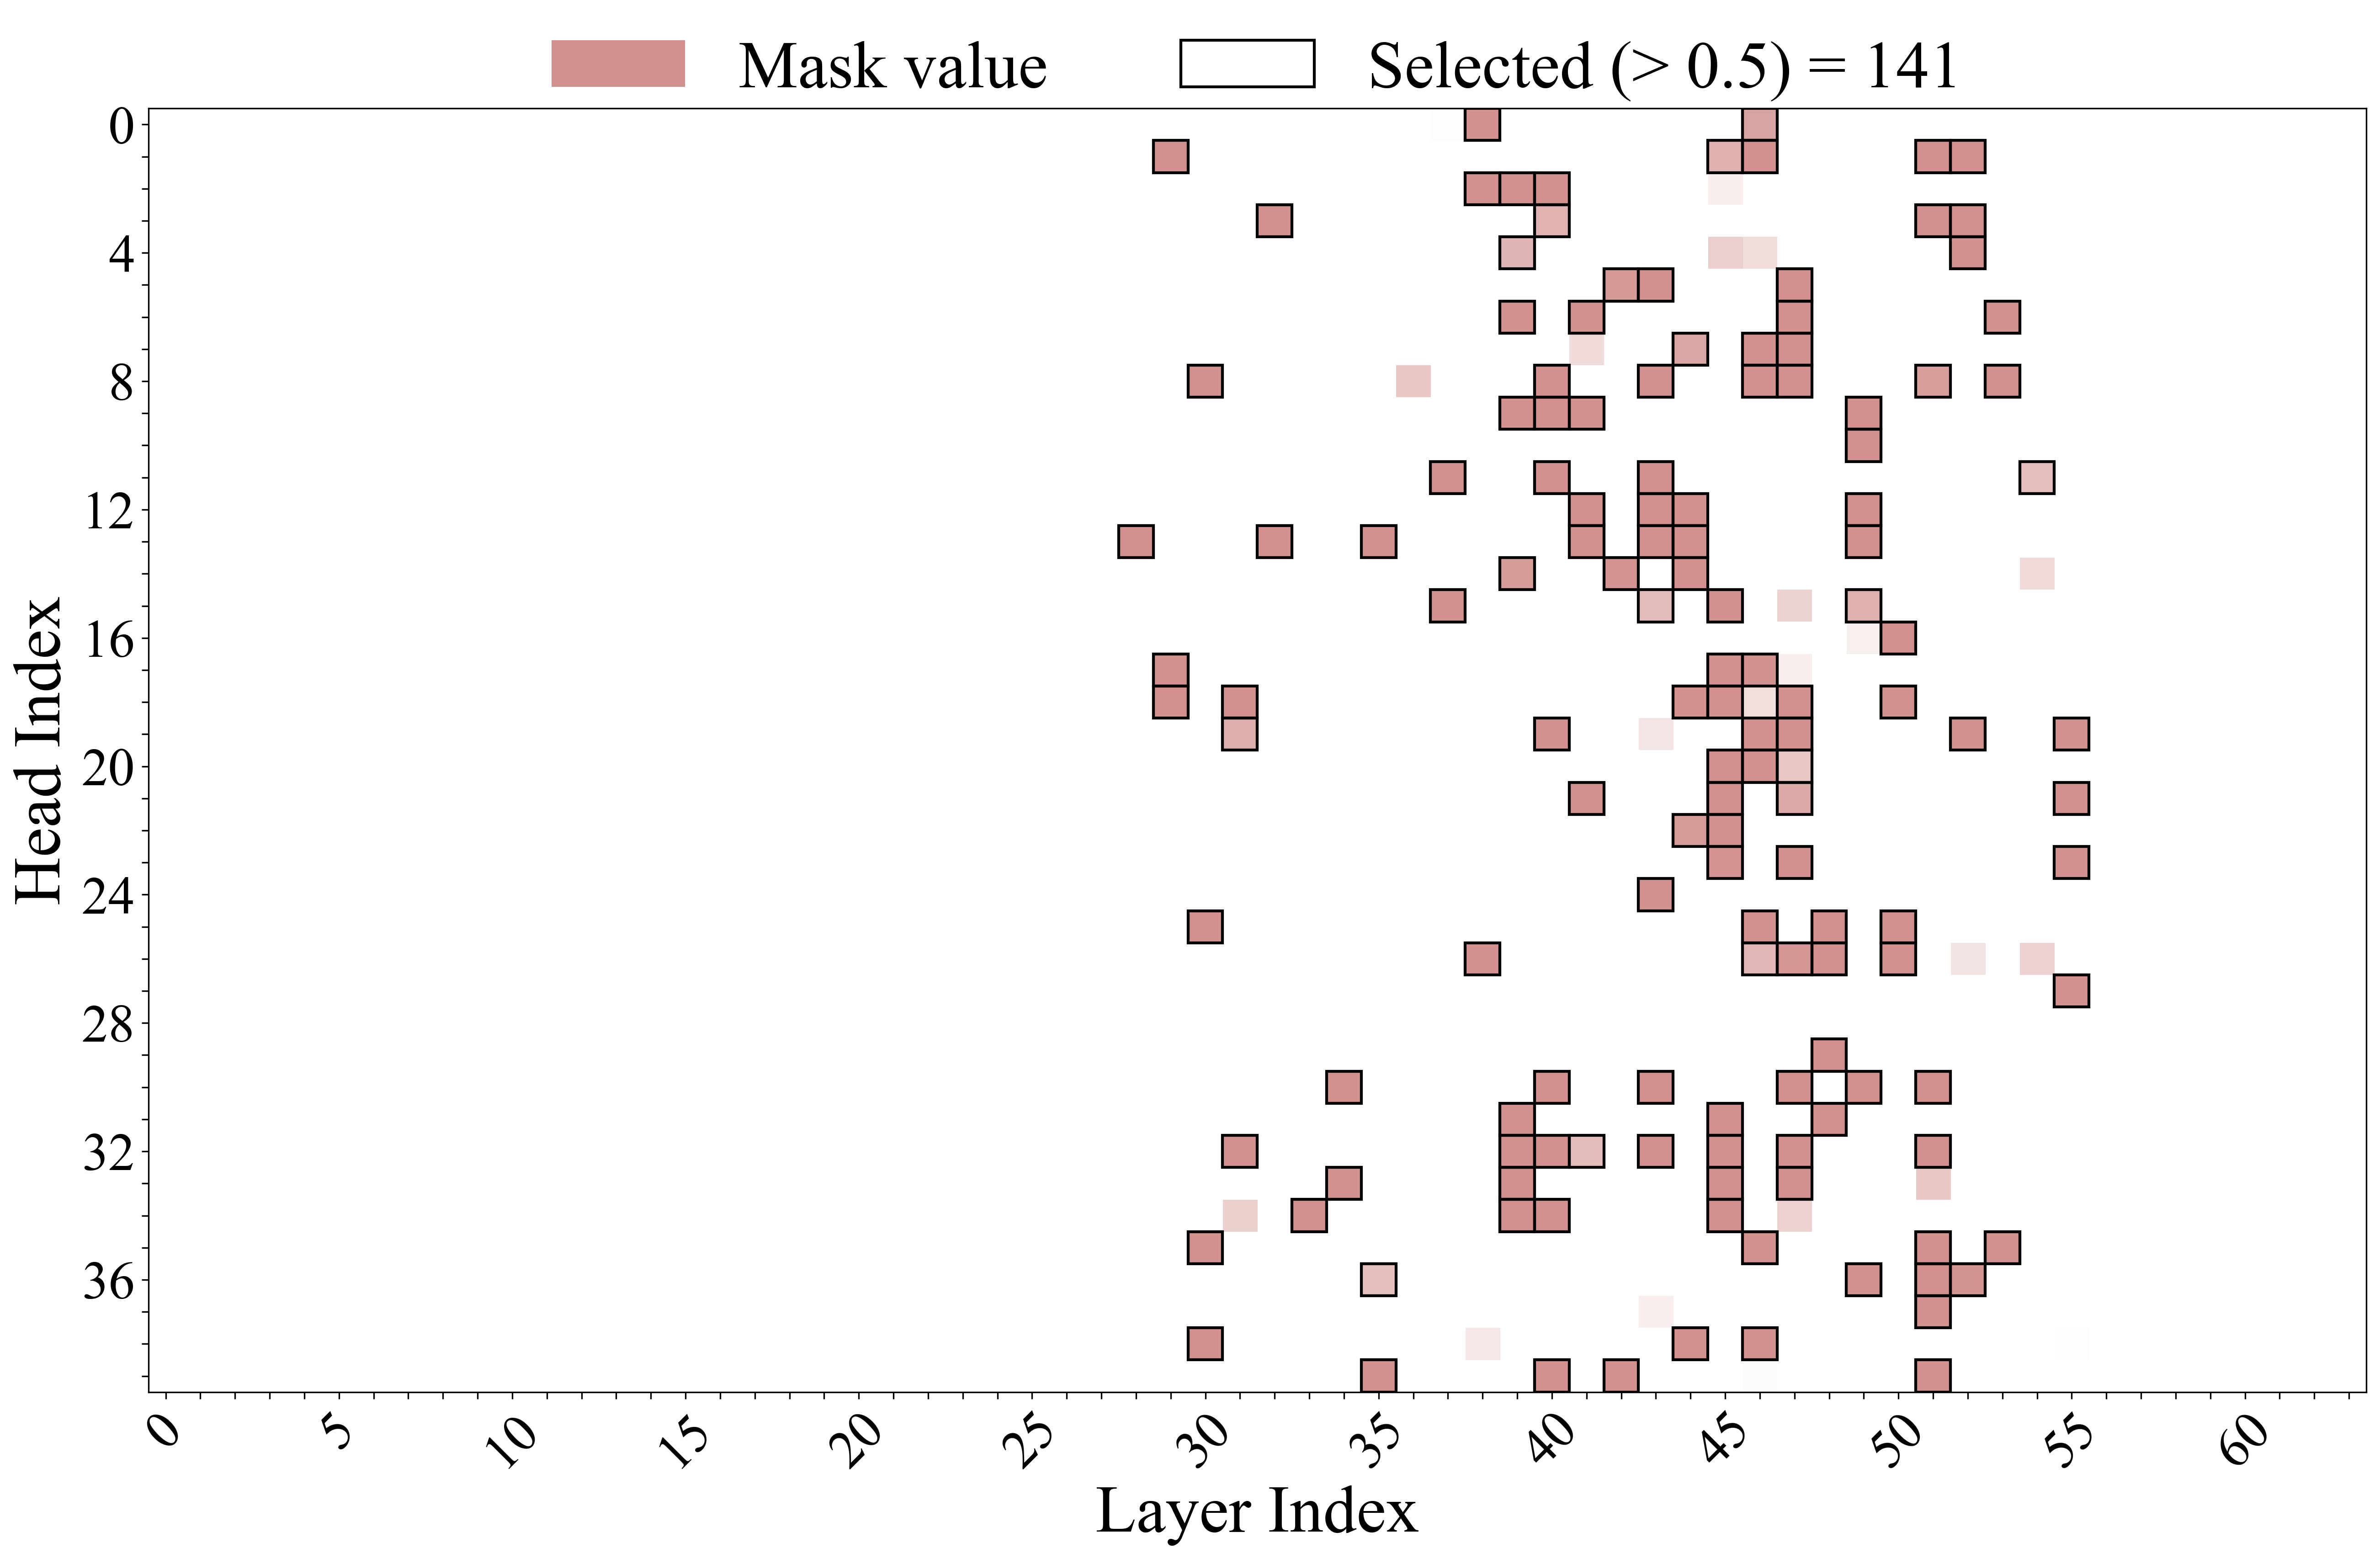

In [25]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret

_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in selected_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1, 1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1.5, label=f"Selected (> 0.5) = {len(selected_heads)}"),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


---
## Attention pattern visualization for selected heads

`get_attention_matrices` runs one forward pass with `output_attentions=True` and returns
an `AttentionInformation` object: `.attention_matrices` is `(n_layers, n_heads, seq, seq)`.

`visualize_attn_matrix` uses **circuitsvis** to show which source tokens the last query
token (or any `q_index`) attends to for a given `(layer, head)`.

The cells below visualize:
1. Each head in `selected_heads` on the **source** (C++) prompt.
2. Each head on the **destination** (Python) prompt — shows what changes after patching.

In [26]:
from src.attention import get_attention_matrices, visualize_attn_matrix
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick a pivot instance to inspect — change IDX to explore others
# VIS_IDX = 0
# pair_v, pi_v = pivot_instances[VIS_IDX]

pair_v, pi_v = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
][0]  # Just pick the first matching instance

src_prompt_v = build_cpp_prompt(
    mt, ds.get_sample(pair_v.source_predicate), include_docstring=True
)
dest_prompt_v = build_python_prompt(
    mt,
    ds.get_sample(pair_v.destination_predicate),
    pivot_prefix=pi_v.pivot_prefix,
    include_docstring=True,
)
targ_prompt_v = build_python_prompt(
    mt,
    ds.get_sample(pair_v.source_predicate),  # source_predicate = Python target
    pivot_prefix=pi_v.pivot_prefix,
    include_docstring=True,
)

print(f"Pair: {pair_v.destination_predicate!r} ← {pair_v.source_predicate!r}")
print(
    f"Pivot prefix: {pi_v.pivot_prefix!r}  |  target token: {pi_v.target_top_token!r}"
)
print(f"\nActive heads ({len(selected_heads)}): {selected_heads}")

# One forward pass each — output_attentions=True (eager mode required)
attn_src = get_attention_matrices(src_prompt_v, mt, value_weighted=True)
attn_dest = get_attention_matrices(dest_prompt_v, mt, value_weighted=True)
attn_targ = get_attention_matrices(targ_prompt_v, mt, value_weighted=True)

Pair: 'is_lower' ← 'is_palindrome'
Pivot prefix: 's == s'  |  target token: '[::-'

Active heads (141): [(28, 13), (29, 1), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (30, 38), (31, 18), (31, 19), (31, 32), (32, 3), (32, 13), (33, 34), (34, 30), (34, 33), (35, 13), (35, 36), (35, 39), (37, 11), (37, 15), (38, 0), (38, 2), (38, 26), (39, 2), (39, 4), (39, 6), (39, 9), (39, 14), (39, 31), (39, 32), (39, 33), (39, 34), (40, 2), (40, 3), (40, 8), (40, 9), (40, 11), (40, 19), (40, 30), (40, 32), (40, 34), (40, 39), (41, 6), (41, 9), (41, 12), (41, 13), (41, 21), (41, 32), (42, 5), (42, 14), (42, 39), (43, 5), (43, 8), (43, 11), (43, 12), (43, 13), (43, 15), (43, 24), (43, 30), (43, 32), (44, 7), (44, 12), (44, 13), (44, 14), (44, 18), (44, 22), (44, 38), (45, 1), (45, 15), (45, 17), (45, 18), (45, 20), (45, 21), (45, 22), (45, 23), (45, 31), (45, 32), (45, 33), (45, 34), (46, 0), (46, 1), (46, 7), (46, 8), (46, 17), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (46, 38), (47, 5), 

In [27]:
top_heads = sorted(
    selected_heads, key=lambda x: mask.values[LAYERS.index(x[0]), x[1]], reverse=True
)
for layer_idx, head_idx in top_heads:
    mask_val = mask.values[LAYERS.index(layer_idx), head_idx].item()
    print(f"Layer {layer_idx} Head {head_idx} (mask={mask_val:.4f}):")

Layer 28 Head 13 (mask=1.0000):
Layer 29 Head 1 (mask=1.0000):
Layer 29 Head 17 (mask=1.0000):
Layer 29 Head 18 (mask=1.0000):
Layer 30 Head 8 (mask=1.0000):
Layer 30 Head 25 (mask=1.0000):
Layer 30 Head 35 (mask=1.0000):
Layer 31 Head 18 (mask=1.0000):
Layer 31 Head 32 (mask=1.0000):
Layer 32 Head 3 (mask=1.0000):
Layer 32 Head 13 (mask=1.0000):
Layer 33 Head 34 (mask=1.0000):
Layer 34 Head 30 (mask=1.0000):
Layer 34 Head 33 (mask=1.0000):
Layer 35 Head 13 (mask=1.0000):
Layer 35 Head 39 (mask=1.0000):
Layer 37 Head 11 (mask=1.0000):
Layer 37 Head 15 (mask=1.0000):
Layer 38 Head 0 (mask=1.0000):
Layer 38 Head 2 (mask=1.0000):
Layer 38 Head 26 (mask=1.0000):
Layer 39 Head 9 (mask=1.0000):
Layer 39 Head 31 (mask=1.0000):
Layer 39 Head 32 (mask=1.0000):
Layer 39 Head 33 (mask=1.0000):
Layer 39 Head 34 (mask=1.0000):
Layer 40 Head 2 (mask=1.0000):
Layer 40 Head 8 (mask=1.0000):
Layer 40 Head 9 (mask=1.0000):
Layer 40 Head 11 (mask=1.0000):
Layer 40 Head 19 (mask=1.0000):
Layer 40 Head 32 

In [28]:
# # Visualize each selected head on the C++ source prompt (last-token query)
# # What does this head attend to when the model processes the C++ goal signal?

# print("=" * 80)
# print("ATTENTION PATTERNS — C++ source prompt (last token query)")
# print("=" * 80)

# for layer, head in top_heads[:5]:
#     mask_val = mask.values[LAYERS.index(layer), head].item()
#     print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
#     mat = attn_src.get_attn_matrix(layer, head)
#     visualize_attn_matrix(mat, attn_src.tokenized_prompt, q_index=-1, start_from=0)

In [29]:
aggregated_src_attn = []
for layer, head in top_heads[:40]:
    aggregated_src_attn.append(torch.Tensor(attn_src.get_attn_matrix(layer, head)))

aggregated_src_attn = torch.stack(
    aggregated_src_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_src_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(mean_attn, attn_src.tokenized_prompt, q_index=-1, start_from=0)

In [30]:
# # Same heads on the Python destination prompt — what does the dest model attend to?
# # Comparing src vs dest attention for the same head reveals what the patch is changing.

# print("=" * 80)
# print("ATTENTION PATTERNS — Python destination prompt (last token query)")
# print("=" * 80)

# for layer, head in top_heads[:5]:
#     mask_val = mask.values[LAYERS.index(layer), head].item()
#     print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
#     mat = attn_dest.get_attn_matrix(layer, head)
#     visualize_attn_matrix(mat, attn_dest.tokenized_prompt, q_index=-1, start_from=0)

In [31]:
aggregated_dest_attn = []
for layer, head in top_heads[:40]:
    aggregated_dest_attn.append(torch.Tensor(attn_dest.get_attn_matrix(layer, head)))

aggregated_dest_attn = torch.stack(
    aggregated_dest_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_dest_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(
    mean_attn, attn_dest.tokenized_prompt, q_index=-1, start_from=0
)  # (n_selected_heads, seq_len, seq_len)

In [32]:
# # Visualize each selected head on the C++ source prompt (last-token query)
# # What does this head attend to when the model processes the C++ goal signal?

# print("=" * 80)
# print("ATTENTION PATTERNS — python target prompt (last token query)")
# print("=" * 80)

# for layer, head in top_heads[:5]:
#     mask_val = mask.values[LAYERS.index(layer), head].item()
#     print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
#     mat = attn_targ.get_attn_matrix(layer, head)
#     visualize_attn_matrix(mat, attn_targ.tokenized_prompt, q_index=-1, start_from=0)

In [33]:
aggregated_target_attn = []
for layer, head in top_heads[:40]:
    aggregated_target_attn.append(torch.Tensor(attn_targ.get_attn_matrix(layer, head)))

aggregated_target_attn = torch.stack(
    aggregated_target_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_target_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(
    mean_attn, attn_targ.tokenized_prompt, q_index=-1, start_from=0
)  # (n_selected_heads, seq_len, seq_len)

## Selecting the failed validation samples

In [34]:
import random
from src.utils import experiment_utils
from src.goals.head_loc_attn import augment_pivot_caches, cache_pivot_data

experiment_utils.set_seed(1234)
MODEL_NAME = "Qwen2.5-Coder-32B-Instruct"

ds = HeadLocDataset.load(model_name=MODEL_NAME)
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]
random.shuffle(pivot_instances)

validation_set = pivot_instances[:128]
val_pivot_cache = cache_pivot_data(
    mt=mt,
    pivot_instances=validation_set,
    ds=ds,
    layers=LAYERS,
    include_docstring=True,
    precompute_deltas=False,
    cache_batch_size=64,
)

_aug_val_caches = augment_pivot_caches(
    mt=mt,
    pivot_caches=val_pivot_cache,
    include_docstring=True,
    cache_batch_size=64,
)


2026-03-23 17:06:36 src.utils.experiment_utils INFO     setting all seeds to 1234


2026-03-23 17:06:36 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/Qwen2.5-Coder-32B-Instruct.json
2026-03-23 17:06:36 src.goals.head_loc_attn INFO     cache_pivot_data: 128 instances | precompute_deltas=False | cache_batch_size=64
2026-03-23 17:06:40 src.goals.head_loc_attn DEBUG      targ probs: 64/128
2026-03-23 17:06:44 src.goals.head_loc_attn DEBUG      targ probs: 128/128
2026-03-23 17:06:44 src.goals.head_loc_attn DEBUG      Building cache 1/128: is_strictly_sorted ← all_positive prefix='True and all'
2026-03-23 17:06:44 src.goals.head_loc_attn DEBUG      Building cache 2/128: is_upper ← is_digit_string prefix='all(c.is'
2026-03-23 17:06:44 src.goals.head_loc_attn DEBUG      Building cache 3/128: is_palindrome ← ends_with_vowel prefix='not not s.lower()[-1'
2026-03-23 17:06:44 src.goals.head_loc_attn DEBUG      Building cache 4/128: is_strictly_decreasing ← all_positive prefix='not any'
2026-03-23 17:0

In [36]:
# IDX = 5
# cache_sample = _aug_val_caches[IDX]
# rich_print("---- Source Prompt ----")
# rich_print(f"[white]{cache_sample.src_prompt}[/white]")

# rich_print("---- Destination Prompt ----")
# rich_print(f"{cache_sample.dest_prompt}")

# cache_sample.pivot_instance

In [38]:
from src.goals.head_loc_attn import (
    get_o_proj_inputs_batch,
    precompute_per_head_deltas_batch,
    forward_with_masked_patch,
)
from src.tokens import prepare_input
from src.utils.metrics import recall as recall_metric
from tqdm.auto import tqdm


all_predictions: list[list[str]] = []
all_targets: list[str] = []

for cache in tqdm(_aug_val_caches):
    if cache.per_head_deltas is not None:
        delta = cache.per_head_deltas  # (L, H, E) — eager path
    else:
        combined = get_o_proj_inputs_batch(
            mt, [cache.src_prompt, cache.dest_prompt], layers=LAYERS
        )
        src_o = {ly: combined[ly][:1] for ly in LAYERS}
        dest_o = {ly: combined[ly][1:] for ly in LAYERS}
        delta = precompute_per_head_deltas_batch(mt, src_o, dest_o, layers=LAYERS)[0]

    dest_inputs = prepare_input([cache.dest_prompt], tokenizer=mt)
    logits = forward_with_masked_patch(
        mt, dest_inputs, delta, mask, layers=LAYERS
    )  # (vocab,)
    top_k_ids = logits.topk(5).indices.tolist()
    top_k_toks = [mt.tokenizer.decode([i]) for i in top_k_ids]
    all_predictions.append(top_k_toks)
    all_targets.append(cache.pivot_instance.target_top_token)

recall_metric(all_predictions, all_targets)

  0%|          | 0/128 [00:00<?, ?it/s]

[0.7890625, 0.90625, 0.921875, 0.9375, 0.9453125]

In [39]:
all_predictions[:5], all_targets[:5]

([['(x', '(element', '(item', '(i', '(isinstance'],
  ['upper', 'alpha', '_upper', 'alnum', 'numeric'],
  [']', ':]', '].', ':].', ']['],
  ['(x', '(element', '(num', '(item', '(not'],
  ['2', '3', '1', '0', ' ']],
 ['(x', 'numeric', ']', '(x', '3'])

In [40]:
failed_at_1 = [
    idx for idx, (preds, target) in enumerate(zip(all_predictions, all_targets))
    if target != preds[0]
]
len(failed_at_1), len(all_predictions)

(28, 128)

In [41]:
rich_print(_aug_val_caches[0])

PivotCache(
    pivot_instance=PivotInstance(
        pivot_prefix='True and all',
        dest_top_token='(lst',
        target_top_token='(x'
    ),
    dest_prompt='<|im_start|>system\nYou are a helpful assistant proficient in programming. When 
completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside 
the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Python function 
below.<|im_end|>\n<|im_start|>assistant\n<code>\ndef is_strictly_sorted(lst: list[int]) -> bool:\n  
"""Return True if lst is sorted in strictly increasing order (no equal adjacent elements)."""\n    
return True and all',
    log_p_target=tensor([-21.3990, -21.1178, -20.2428,  ..., -23.0259, -23.0259, -23.0259]),
    per_head_deltas=None,
    src_sample=SinglePredicateSample(
        predicate_name='all_positive',
        variable_type='list[int]',
        variable_name='lst',
        python_incomplete_code='def all_positive(lst: list[int]) -> bool:\n    return',
        cpp_incomplete_code='bool allPositive(vector<int> lst) { return',
        unit_tests=[
            ([1, 2, 3], True),
            ([5, 10, 15], True),
            ([1, 2, 3, 4], True),
            ([1, 0, 3], False),
            ([2, 4, -1], False),
            ([1, 2, 0], False)
        ],
        function_name='all_positive',
        docstring='Return True if every element in lst is greater than zero.',
        augmentation=None
    ),
    dest_sample=SinglePredicateSample(
        predicate_name='is_strictly_sorted',
        variable_type='list[int]',
        variable_name='lst',
        python_incomplete_code='def is_strictly_sorted(lst: list[int]) -> bool:\n    return',
        cpp_incomplete_code='bool isStrictlySorted(vector<int> lst) { return',
        unit_tests=[
            ([1, 2, 3], True),
            ([1, 2, 3, 4, 5], True),
            ([1, 2], True),
            ([1, 1, 2], False),
            ([3, 2, 1], False),
            ([1, 3, 2], False)
        ],
        function_name='is_strictly_sorted',
        docstring='Return True if lst is sorted in strictly increasing order (no equal adjacent 
elements).',
        augmentation=None
    ),
    src_prompt='<|im_start|>system\nYou are a helpful assistant proficient in programming. When 
completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside 
the <code> </code> tags.<|im_end|>\n<|im_start|>user\nComplete the Prolog predicate 
below.<|im_end|>\n<|im_start|>assistant\n<code>\n% Return True if every element in lst is greater 
than zero.\nall_positive(Lst) :- '
)

## Qualitative Analysis

In [43]:
selected_instances = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_upper"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_instances)

5

In [46]:
import torch
from rich.console import Console
from rich.table import Table

from src.goals.head_loc_attn import (
    HeadMask,
    forward_with_masked_patch,
    get_o_proj_inputs_batch,
    precompute_per_head_deltas_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ──────────────────
_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in selected_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads ({100 * binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

METRIC = "logit"  # "logit" or "prob"
MAX_NEW_TOKENS = 32
PATCH_ALL_TOKENS = True  # True  → patch every generated token
# False → patch only the pivot (first token), then greedy

_STOP_IDS = {mt.tokenizer.eos_token_id} | set(
    mt.tokenizer.encode("\n", add_special_tokens=False)
)


def _greedy_continue(mt, input_ids, attention_mask, max_new_tokens):
    """Plain greedy generation — no patching."""
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            out = mt._model(input_ids=input_ids, attention_mask=attention_mask)
            next_tok = int(out.logits[0, -1].argmax())
            generated.append(next_tok)
            if next_tok in _STOP_IDS:
                break
            input_ids = torch.cat(
                [input_ids, torch.tensor([[next_tok]], device=input_ids.device)], dim=1
            )
            attention_mask = torch.cat(
                [
                    attention_mask,
                    torch.ones(
                        (1, 1), dtype=attention_mask.dtype, device=attention_mask.device
                    ),
                ],
                dim=1,
            )
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def _patched_generate(mt, dest_inputs, per_head_deltas, mask, layers, max_new_tokens):
    """Greedy generation with head patching applied at every token position."""
    input_ids = dest_inputs["input_ids"].clone()
    attention_mask = dest_inputs["attention_mask"].clone()
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
            # forward_with_masked_patch always patches the last token position,
            # so as the sequence grows the intervention follows the generation frontier.
            logits = forward_with_masked_patch(
                mt, inputs, per_head_deltas, mask, layers
            )
            next_tok = int(logits.argmax())
            generated.append(next_tok)
            if next_tok in _STOP_IDS:
                break
            input_ids = torch.cat(
                [input_ids, torch.tensor([[next_tok]], device=input_ids.device)], dim=1
            )
            attention_mask = torch.cat(
                [
                    attention_mask,
                    torch.ones(
                        (1, 1), dtype=attention_mask.dtype, device=attention_mask.device
                    ),
                ],
                dim=1,
            )
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


Binary mask: 141 active heads / 2560 total heads (5.51%)


In [48]:
import logging
from src.goals.head_loc_module import _top5_str
from src.utils.metrics import recall, AggregateMetric
from src.goals.head_loc_pivot import (
    build_cpp_prompt,
    build_python_prompt,
    build_java_prompt,
    build_haskell_prompt,
    build_prolog_prompt,
    build_rust_prompt,
)

logger = logging.getLogger(__name__)
console = Console(width=130, highlight=False)

K_RECALL = 5  # recall@k to report

# Accumulate across instances
_dest_preds_all = []
_patched_preds_all = []
_targets_all = []
_ie_all = []

# for idx, (pair, pi) in enumerate(selected_instances):
#     src_sample = ds.get_sample(pair.source_predicate)
#     dest_sample = ds.get_sample(pair.destination_predicate)
#     targ_sample = ds.get_sample(pair.source_predicate)
#     pfx = f"return {pi.pivot_prefix}" if pi.pivot_prefix else ""

#     # src_prompt  = build_cpp_prompt(mt, src_sample, include_docstring=True)
#     # src_prompt = build_java_prompt(mt, src_sample, include_docstring=True)
#     src_prompt = build_rust_prompt(mt, src_sample, include_docstring=True)
#     dest_prompt = build_python_prompt(
#         mt, dest_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
#     )
#     targ_prompt = build_python_prompt(
#         mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
#     )

#     # pfx = '""" Check if'
#     # dest_prompt = dest_prompt.split('"""')[0] + pfx 
#     # targ_prompt = targ_prompt.split('"""')[0] + pfx
#     ---------------------------------------------------------------------------


for idx in failed_at_1:
    src_prompt = _aug_val_caches[idx].src_prompt
    dest_prompt = _aug_val_caches[idx].dest_prompt
    pair, pi = validation_set[idx]
    targ_sample = ds.get_sample(pair.source_predicate)
    targ_prompt = build_python_prompt(
        mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
    )
    pfx = f"return {pi.pivot_prefix}" if pi.pivot_prefix else ""
    # ---------------------------------------------------------------------------

    logger.debug(
        f"\n{'=' * 80}\nInstance {idx}: {pair.destination_predicate} ← {pair.source_predicate}  prefix={pi.pivot_prefix!r}"
    )
    logger.debug(f"[src prompt]\n{src_prompt}")
    logger.debug(f"[dest prompt]\n{dest_prompt}")
    logger.debug(f"[targ prompt]\n{targ_prompt}")

    target_tok_id = mt.tokenizer.encode(pi.target_top_token, add_special_tokens=False)[
        0
    ]

    dest_inputs = prepare_input([dest_prompt], tokenizer=mt)
    targ_inputs = prepare_input([targ_prompt], tokenizer=mt)

    # ── Per-head deltas ───────────────────────────────────────────────────────
    combined_o = get_o_proj_inputs_batch(mt, [src_prompt, dest_prompt], LAYERS)
    src_o = {l: combined_o[l][:1] for l in LAYERS}
    dest_o = {l: combined_o[l][1:] for l in LAYERS}
    per_head_deltas = precompute_per_head_deltas_batch(
        mt, src_o, dest_o, LAYERS
    )  # (1, L, H, E)

    # ── Three forward passes ──────────────────────────────────────────────────
    with torch.no_grad():
        logits_dest = mt._model(**dest_inputs).logits[0, -1]
        logits_targ = mt._model(**targ_inputs).logits[0, -1]
        logits_patched = forward_with_masked_patch(
            mt, dict(dest_inputs), per_head_deltas[0], binary_mask, LAYERS
        )

    score_dest = get_score(logits_dest, target_tok_id, metric=METRIC)
    score_targ = get_score(logits_targ, target_tok_id, metric=METRIC)
    score_patched = get_score(logits_patched, target_tok_id, metric=METRIC)
    ie = (score_patched - score_dest) / (score_targ - score_dest + 1e-8)

    logger.debug(
        f"[dest]    top5: {_top5_str(mt, logits_dest, METRIC)}  target({pi.target_top_token!r})={score_dest:.4f}"
    )
    logger.debug(
        f"[targ]    top5: {_top5_str(mt, logits_targ, METRIC)}  target({pi.target_top_token!r})={score_targ:.4f}"
    )
    logger.debug(
        f"[patched] top5: {_top5_str(mt, logits_patched, METRIC)}  target({pi.target_top_token!r})={score_patched:.4f}  IE={ie:.3f}"
    )

    # ── Accumulate ───────────────────────────────────────────────────────────
    def _topk_toks(logits, k):
        return [mt.tokenizer.decode([i]) for i in logits.topk(k).indices.tolist()]

    _dest_preds_all.append(_topk_toks(logits_dest, K_RECALL))
    _patched_preds_all.append(_topk_toks(logits_patched, K_RECALL))
    _targets_all.append(pi.target_top_token)
    _ie_all.append(ie)

    # ── Generation ───────────────────────────────────────────────────────────
    src_gen = _greedy_continue(
        mt,
        prepare_input([src_prompt], tokenizer=mt)["input_ids"],
        prepare_input([src_prompt], tokenizer=mt)["attention_mask"],
        MAX_NEW_TOKENS,
    )
    dest_gen = _greedy_continue(
        mt,
        dest_inputs["input_ids"].clone(),
        dest_inputs["attention_mask"].clone(),
        MAX_NEW_TOKENS,
    )
    targ_gen = _greedy_continue(
        mt,
        targ_inputs["input_ids"].clone(),
        targ_inputs["attention_mask"].clone(),
        MAX_NEW_TOKENS,
    )

    if PATCH_ALL_TOKENS:
        # Patch at every generated token position (same delta injected each step).
        patched_gen = _patched_generate(
            mt,
            dict(dest_inputs),
            per_head_deltas[0],
            binary_mask,
            LAYERS,
            MAX_NEW_TOKENS,
        )
    else:
        # Patch only the pivot (first token), then continue greedily.
        patched_first_tok = int(logits_patched.argmax())
        _dev = dest_inputs["input_ids"].device
        _ids_p = torch.cat(
            [
                dest_inputs["input_ids"],
                torch.tensor([[patched_first_tok]], device=_dev),
            ],
            dim=1,
        )
        _msk_p = torch.cat(
            [
                dest_inputs["attention_mask"],
                torch.ones(
                    (1, 1), dtype=dest_inputs["attention_mask"].dtype, device=_dev
                ),
            ],
            dim=1,
        )
        patched_gen = mt.tokenizer.decode([patched_first_tok]) + _greedy_continue(
            mt, _ids_p, _msk_p, MAX_NEW_TOKENS - 1
        )

    # ── Per-instance table ────────────────────────────────────────────────────
    patch_mode = "patch-all" if PATCH_ALL_TOKENS else "patch-pivot"
    console.print(
        f"\n[bold cyan]Instance {idx}[/bold cyan]  "
        f"[bright_green]{pair.destination_predicate}[/bright_green] ← [bright_red]{pair.source_predicate}[/bright_red]  "
        f"prefix={pi.pivot_prefix!r}  target_tok=[bright_magenta][bold]{pi.target_top_token!r}[/bold][/bright_magenta]  [{patch_mode}]"
    )
    table = Table(highlight=False, show_header=True, pad_edge=False, box=None)
    table.add_column("run", style="bright_cyan", width=12)
    table.add_column(METRIC, style="salmon1", width=8, justify="right")
    table.add_column("IE", style="bright_magenta", width=7, justify="right")
    table.add_column("generation", width=85)
    table.add_row("src (C++)", "—", "—", f"{src_gen}")
    table.add_row(
        "dest (base)",
        f"{score_dest:.4f}",
        "—",
        f"[bright_yellow]{pfx}[/bright_yellow]{dest_gen}",
    )
    table.add_row(
        "targ (sky)",
        f"{score_targ:.4f}",
        "—",
        f"[bright_yellow]{pfx}[/bright_yellow]{targ_gen}",
    )
    table.add_row(
        "patched",
        f"{score_patched:.4f}",
        f"{ie:.3f}",
        f"[bright_yellow]{pfx}[/bright_yellow]{patched_gen}",
    )
    console.print(table)

# ── Aggregate summary ─────────────────────────────────────────────────────────
recall_dest = recall(_dest_preds_all, _targets_all)
recall_patched = recall(_patched_preds_all, _targets_all)
ie_agg = AggregateMetric.aggregate(_ie_all)

summary = Table(
    title=f"Summary  (N={len(_targets_all)})", highlight=False, show_header=True
)
summary.add_column("run", style="cyan")
summary.add_column("IE  mean±se", style="salmon1", justify="right")
for k in range(1, K_RECALL + 1):
    summary.add_column(f"recall@{k}", style="bright_yellow", justify="right")
summary.add_row(
    "dest (baseline)",
    "—",
    *[f"{recall_dest[k - 1]:.3f}" for k in range(1, K_RECALL + 1)],
)
summary.add_row(
    "patched",
    str(ie_agg),
    *[f"{recall_patched[k - 1]:.3f}" for k in range(1, K_RECALL + 1)],
)
console.print()
console.print(summary)


2026-03-23 17:21:06 __main__ DEBUG    
Instance 1: is_upper ← is_digit_string  prefix='all(c.is'
2026-03-23 17:21:06 __main__ DEBUG    [src prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Rust function below.<|im_end|>
<|im_start|>assistant
<code>
/// Return True if every character in s is a digit.
fn is_digit_string(s: &str) -> bool {
    return 
2026-03-23 17:21:06 __main__ DEBUG    [dest prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_upper(s: str) -> bool:
    """Return True if all alphabetic characters in s are upper

2026-03-23 17:21:09 __main__ DEBUG    [dest]    top5: [ "'upper'" (32.00), "'alpha'" (27.38), "'lower'" (22.00), "'_upper'" (20.00), "' upper'" (19.75) ]  target('numeric')=17.7500
2026-03-23 17:21:09 __main__ DEBUG    [targ]    top5: [ "'_digit'" (27.38), "'numeric'" (26.38), "'decimal'" (24.50), "'Digit'" (23.50), "'digit'" (23.50) ]  target('numeric')=26.3750
2026-03-23 17:21:09 __main__ DEBUG    [patched] top5: [ "'upper'" (36.25), "'alpha'" (30.00), "'_upper'" (25.75), "'alnum'" (25.25), "'numeric'" (24.88) ]  target('numeric')=24.8750  IE=0.826


Instance 1  is_upper ← is_digit_string  prefix='all(c.is'  target_tok='numeric'

run              logit       IE  generation                                                                           
src (C++)            —        —   s.chars().all(|c| c.is_digit(10));                                                  
                                 }                                                                                    
                                                                                                                      
                                 fn main() {                                                                          
                                     let test_str = "12345";                                                          
dest (base)    17.7500        —  return all(c.isupper() for c in s if c.isalpha())                                    
                                 </code>                                                                              
                                                                                                                      
                                 This function checks if all alphabetic characters in the input string `s` are        
                                 uppercase.                                                                           
targ (sky)     26.3750        —  return all(c.is_digit() for c in s)                                                  
                                 </code>                                                                              
                                                                                                                      
                                 There's a small mistake in the code above. The correct method to check if a character
                                 is a digit is                                                                        
patched        24.8750    0.826  return all(c.isupper() for c in s if c.isalpha())                                    
                                 </code>                                                                              
                                                                                                                      
                                 This function `is_upper` takes a string `s` as input and returns `True

2026-03-23 17:21:20 __main__ DEBUG    
Instance 4: is_even ← is_divisible_by_three  prefix='not n % '
2026-03-23 17:21:20 __main__ DEBUG    [src prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Rust function below.<|im_end|>
<|im_start|>assistant
<code>
/// Return True if n is divisible by three.
fn is_divisible_by_three(n: i64) -> bool {
    return 
2026-03-23 17:21:20 __main__ DEBUG    [dest prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_even(n: int) -> bool:
    """Return True if n is an even integer."""
    return not

Instance 4  is_even ← is_divisible_by_three  prefix='not n % '  target_tok='3'

... (76 outputs left out)

2026-03-23 17:26:16 __main__ DEBUG    
Instance 126: all_even ← is_strictly_decreasing  prefix='False or not any(x'
2026-03-23 17:26:16 __main__ DEBUG    [src prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Haskell function below.<|im_end|>
<|im_start|>assistant
<code>
-- | Return True if lst is sorted in strictly decreasing order.
isStrictlyDecreasing :: [Int] -> Bool
isStrictlyDecreasing lst = 
2026-03-23 17:26:16 __main__ DEBUG    [dest prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_even(lst: list[int]) -> bool:
    

Instance 126  all_even ← is_strictly_decreasing  prefix='False or not any(x'  target_tok=' <='

run              logit       IE  generation                                                                           
src (C++)            —        —   all (\(x, y) -> x > y) (zip lst (tail lst))                                         
                                 </code>                                                                              
                                                                                                                      
                                 This function checks if a list of integers is sorted                                 
dest (base)     9.9375        —  return False or not any(x % 2 != 0 for x in lst)                                     
                                 </code>                                                                              
                                                                                                                      
                                 This function checks if all elements in the list `lst` are even. It uses a           
targ (sky)     23.1250        —  return False or not any(x <= y for x, y in zip(lst, lst[1:]))                        
                                 </code>                                                                              
                                                                                                                      
                                 This function checks if a list of integers is sorted in strictly decreasing order    
patched        19.8750    0.754  return False or not any(x > y for x, y in zip(lst, lst[1:])) and all(x % 2 == 0 for x
                                 in lst)                                                                              
                                 </code>

                                    Summary  (N=28)                                     
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ run             ┃ IE  mean±se ┃ recall@1 ┃ recall@2 ┃ recall@3 ┃ recall@4 ┃ recall@5 ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━┩
│ dest (baseline) │           — │    0.107 │    0.250 │    0.357 │    0.429 │    0.536 │
│ patched         │ 0.55 ± 0.07 │    0.143 │    0.750 │    0.821 │    0.893 │    0.929 │
└─────────────────┴─────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

In [49]:
from src.functional import generate_with_patch

prompt = src_prompt
gen = generate_with_patch(
    mt=mt,
    inputs=prompt,
    n_gen_per_prompt=5,
    max_new_tokens=32,
    do_sample=True,
    remove_prefix=True,
)

In [50]:
rich_print(f"[white]{prompt}[white][salmon1]{gen[3]}[/salmon1]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make 
sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Rust function below.<|im_end|>
<|im_start|>assistant
<code>
/// Return True if s reads the same forwards and backwards.
fn is_palindrome(s: &str) -> bool {
    return  s.chars().eq(s.chars().rev());
}
</code>

This function `is_palindrome` takes a string slice `&str` as an argument and